# Aula 9 — Prática demonstrativa: detectar, avaliar e agrupar copas de árvores

**Disciplina:** IA e Visão Computacional na Análise Geoespacial

**Dados:** DJI Mavic 3M, voo de 25/09/2026 (~11h25). O notebook lê **direto os ortomosaicos do ODM** (RGB e multiespectral) e recorta sozinho um quadrado da área.

**Etapas:**
1. conhecer os dados (cor verdadeira, falsa-cor, NDVI, NDRE) e corrigir o deslocamento entre RGB e multiespectral;
2. detectar as copas com o **DeepForest ou detectree2** (modelo pré-treinado, só inferência);
3. avaliar a detecção (visualmente ou com pontos de referência, se houver);
4. agrupar as copas em **morfotipos** com K-means;
5. separar automaticamente as copas **típicas** de cada grupo, que seguem para a Aula 10.

> Não vamos identificar espécies: não temos essa informação. **Morfotipo ≠ espécie.**

| Tempo | Etapa | Seções |
|---|---|---|
| 0–5 min | Dados e recorte | 0 a 3 |
| 5–10 min | Falsa-cor, NDVI e NDRE | 4 |
| 10–20 min | Detecção e escolha do limiar | 5 e 6 |
| 20–32 min | Atributos, agrupamento, mapa e galeria | 7 a 10 |
| 32–40 min | Copas típicas e nomes dos grupos | 11 |
| 40–45 min | Síntese | 12 |

**Preparação (única):** subir os dois ortomosaicos para o Drive, ajustar os caminhos na seção 1


## 0. Instalação e acesso ao Drive

In [35]:
!pip install -q rasterio geopandas scikit-learn scikit-image deepforest

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Configuração

- `RGB_PATH` e `MS_PATH`: os ortomosaicos como saíram do ODM (em UTM).
- `DESLOC_X` e `DESLOC_Y`: deslocam o quadrado, em metros, a partir do centro do mosaico (ex.: `DESLOC_Y = 100` sobe 100 m).
- `CENTRO`: alternativa, coordenada (x, y) em UTM do centro do recorte. Deixe `None` para usar o centro do mosaico, rode a seção 2 e ajuste se o quadrado cair sobre casas ou bordas. Para pegar a coordenada no QGIS, passe o mouse sobre o ponto desejado e leia a barra de status.
- `LADO`: lado do quadrado em metros. 150 m roda em poucos minutos em CPU.

In [37]:
import os, numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject
from rasterio.windows import from_bounds as janela
from rasterio.transform import from_bounds as transf
from rasterio.features import rasterize
from shapely.geometry import box

PASTA       = "/content/drive/MyDrive/Export-earth-engine/YOLO"
RGB_PATH    = f"{PASTA}/PNMBT-2026-09-25-cor-verdadeira.tif"     # ortomosaico RGB do ODM
MS_PATH     = f"{PASTA}/PNMBT-2026-09-25-orthophoto.tif"      #ortomosaico multiespectral do ODM
CENTRO      = None          # (x, y) em UTM; None = centro do mosaico
DESLOC_X    = 0             # metros a partir do centro: + direita, - esquerda (só se CENTRO = None)
DESLOC_Y    = 100             # metros a partir do centro: + para cima, - para baixo (só se CENTRO = None)
LADO        = 150           # lado do recorte (m)
RES_ALVO    = 0.10          # resolução de trabalho (m): a do treino do DeepForest
REF_PONTOS  = None          # opcional: f"{PASTA}/arvores_referencia.gpkg" (um ponto por árvore)
CROWNS_PATH = None          # opcional: copas já detectadas (pula o DeepForest)
USAR_DETECTREE2 = True      # True = usa o detectree2 (seção 5b) no lugar do DeepForest
SEGUIR_COM = "deepforest"   # copas usadas daqui em diante: "deepforest" ou "detectree2"

# Ordem das bandas no multiespectral: confira na seção 2
MS_G, MS_R, MS_RE, MS_NIR = 2, 1, 4, 3
NIR_PATH, NIR_BANDA = MS_PATH, MS_NIR
RED_PATH, RED_BANDA = MS_PATH, MS_R
RE_PATH,  RE_BANDA  = MS_PATH, MS_RE
G_MS_BANDA  = MS_G
CORRIGIR_DESLOCAMENTO = True
LIMIARES    = [0.2, 0.3, 0.4, 0.5]
OUT_DIR     = f"{PASTA}/saidas"; os.makedirs(OUT_DIR, exist_ok=True)

## 2. Os dados e o recorte

Mostra as bandas de cada arquivo e uma prévia do mosaico inteiro com o quadrado que será recortado (em vermelho).

PNMBT-2026-09-25-cor-verdadeira.tif | bandas: 4 | dtype: uint8 | res: (0.03, 0.03) | SRC: EPSG:32723
   descrições: ('red', 'green', 'blue', None)
PNMBT-2026-09-25-orthophoto.tif | bandas: 5 | dtype: float32 | res: (0.05, 0.05) | SRC: EPSG:32723
   descrições: ('Red', 'Green', 'NIR', 'RedEdge', None)


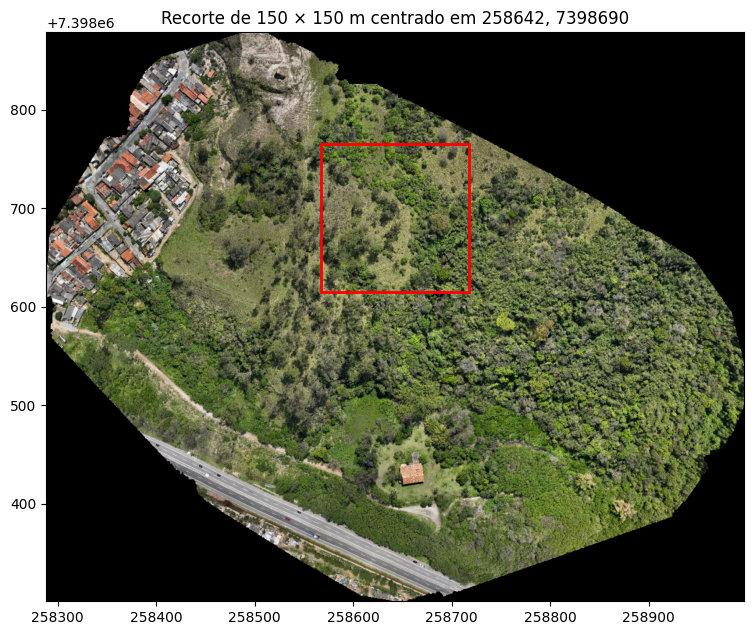

In [38]:
for p in [RGB_PATH, MS_PATH]:
    with rasterio.open(p) as s:
        print(os.path.basename(p), "| bandas:", s.count, "| dtype:", s.dtypes[0],
              "| res:", tuple(round(v, 3) for v in s.res), "| SRC:", s.crs)
        print("   descrições:", s.descriptions)

with rasterio.open(RGB_PATH) as s:
    assert s.crs is not None and s.crs.is_projected, "O mosaico precisa estar em SRC projetado (UTM)."
    b = s.bounds
    if CENTRO is None:
        CENTRO = ((b.left + b.right) / 2 + DESLOC_X, (b.bottom + b.top) / 2 + DESLOC_Y)
    esc = max(s.width, s.height) / 1200
    prev = s.read([1, 2, 3], out_shape=(3, int(s.height / esc), int(s.width / esc)), resampling=Resampling.average)

x0, y0 = CENTRO[0] - LADO / 2, CENTRO[1] - LADO / 2
x1, y1 = x0 + LADO, y0 + LADO
fig, a = plt.subplots(figsize=(9, 9))
a.imshow(np.moveaxis(prev, 0, -1), extent=[b.left, b.right, b.bottom, b.top])
a.add_patch(plt.Rectangle((x0, y0), LADO, LADO, fill=False, edgecolor="red", lw=2))
a.set_title(f"Recorte de {LADO} × {LADO} m centrado em {CENTRO[0]:.0f}, {CENTRO[1]:.0f}")
plt.show()

## 3. Leitura do recorte e alinhamento entre RGB e multiespectral

O RGB é lido já reamostrado para 10 cm e o multiespectral é projetado na mesma grade.
Os mosaicos foram georreferenciados só por GPS (CE90 absoluto ~0,9 m), então podem estar deslocados entre si. O deslocamento é estimado por **correlação de fase** entre as bandas verdes e corrigido.

In [39]:
from skimage.registration import phase_cross_correlation
from scipy.ndimage import shift as desloca

W = H = int(round(LADO / RES_ALVO))
tr = transf(x0, y0, x1, y1, W, H)
with rasterio.open(RGB_PATH) as s:
    crs = s.crs
    w = janela(x0, y0, x1, y1, s.transform)
    rgb = s.read([1, 2, 3], window=w, out_shape=(3, H, W), resampling=Resampling.average,
                 boundless=True, fill_value=0).astype("float32")
    alpha = s.read(4, window=w, out_shape=(H, W), resampling=Resampling.nearest,
                   boundless=True, fill_value=0) if s.count >= 4 else None

def para_grade(path, banda):
    out = np.full((H, W), np.nan, dtype="float32")
    with rasterio.open(path) as s:
        reproject(rasterio.band(s, banda), out, src_nodata=s.nodata,
                  dst_transform=tr, dst_crs=crs, dst_nodata=np.nan,
                  resampling=Resampling.average)
    return out

nir = para_grade(NIR_PATH, NIR_BANDA)
red = para_grade(RED_PATH, RED_BANDA)
re_ = para_grade(RE_PATH, RE_BANDA) if RE_PATH else None

if CORRIGIR_DESLOCAMENTO:
    g_ms = para_grade(MS_PATH, G_MS_BANDA)
    ok = ~np.isnan(g_ms) & ~((rgb >= 250).all(0) | (rgb <= 5).all(0))
    z = lambda a: np.where(ok, (a - np.nanmean(a[ok])) / (np.nanstd(a[ok]) + 1e-9), 0)
    desl, _, _ = phase_cross_correlation(z(rgb[1]), z(g_ms), upsample_factor=10)
    print(f"Deslocamento multiespectral -> RGB: {desl[1]:.1f} px (x), {desl[0]:.1f} px (y) = {np.hypot(*desl) * RES_ALVO:.2f} m")
    corr = lambda a: None if a is None else desloca(a, desl, order=1, cval=np.nan)
    nir, red, re_ = corr(nir), corr(red), corr(re_)

valido = ~np.isnan(nir) & ~((rgb >= 250).all(0) | (rgb <= 5).all(0))
if alpha is not None:
    valido &= alpha > 0
print(f"Grade: {W} x {H} px a {RES_ALVO} m | pixels válidos: {valido.mean():.1%}")

Deslocamento multiespectral -> RGB: 6.0 px (x), -11.8 px (y) = 1.32 m
Grade: 1500 x 1500 px a 0.1 m | pixels válidos: 98.7%


In [40]:
pilha = np.stack([rgb[0], rgb[1], rgb[2], re_, nir]).astype("float32")
pilha[:, ~valido] = np.nan
perfil = dict(driver="GTiff", height=H, width=W, count=5, dtype="float32", crs=crs,
              transform=tr, nodata=np.nan, compress="deflate")
with rasterio.open(f"{OUT_DIR}/recorte_pilha.tif", "w", **perfil) as dst:
    dst.write(pilha)
    for i, nome in enumerate(["R", "G", "B", "RE", "NIR"], 1):
        dst.set_band_description(i, nome)
print("Salvo:", f"{OUT_DIR}/recorte_pilha.tif")

Salvo: /content/drive/MyDrive/Export-earth-engine/YOLO/saidas/recorte_pilha.tif


## 4. Cor verdadeira, falsa-cor, NDVI e NDRE

- **Falsa-cor NIR-R-G:** a vegetação fica vermelha porque a folha reflete muito NIR.
- **NDVI** = (NIR − R) ÷ (NIR + R); **NDRE** = (NIR − RE) ÷ (NIR + RE), mais sensível à clorofila e que satura menos em vegetação densa.

**Para comentar:** copas que parecem iguais em cor verdadeira e ficam diferentes na falsa-cor ou no NDRE.

NDVI com vermelho e NIR do mesmo sensor.


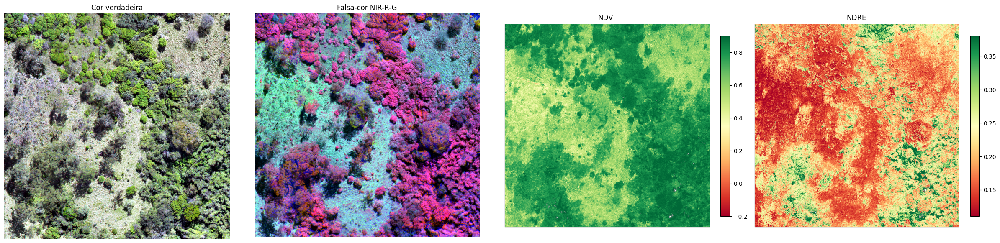

In [41]:
def escala01(a, p=(2, 98)):
    lo, hi = np.nanpercentile(a[valido], p)
    return np.clip((a - lo) / (hi - lo + 1e-9), 0, 1)

if red is not None:
    r_ndvi, nir_ndvi = red, nir
    print("NDVI com vermelho e NIR do mesmo sensor.")
else:
    r_ndvi, nir_ndvi = escala01(rgb[0]), escala01(nir)
    print("Aviso: pseudo-NDVI (vermelho da câmera RGB + NIR reescalados).")

ndvi = (nir_ndvi - r_ndvi) / (nir_ndvi + r_ndvi + 1e-9)
ndvi[~valido] = np.nan
if re_ is not None:     # NDRE: sensível a clorofila e estrutura foliar, útil para separar espécies
    ndre = (nir - re_) / (nir + re_ + 1e-9); ndre[~valido] = np.nan
else:
    ndre = None

rgb_vis   = np.dstack([escala01(rgb[i]) for i in range(3)])
r_falsa = red if red is not None else rgb[0]
falsa_cor = np.dstack([escala01(nir), escala01(r_falsa), escala01(rgb[1])])   # NIR-R-G

fig, ax = plt.subplots(1, 4, figsize=(24, 6))
ax[0].imshow(rgb_vis); ax[0].set_title("Cor verdadeira")
ax[1].imshow(falsa_cor); ax[1].set_title("Falsa-cor NIR-R-G")
im = ax[2].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9); ax[2].set_title("NDVI")
plt.colorbar(im, ax=ax[2], fraction=0.04)
if ndre is not None:
    im2 = ax[3].imshow(ndre, cmap="RdYlGn", vmin=np.nanpercentile(ndre, 2), vmax=np.nanpercentile(ndre, 98)); ax[3].set_title("NDRE")
    plt.colorbar(im2, ax=ax[3], fraction=0.04)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Detecção das copas com o DeepForest

O DeepForest (RetinaNet, um estágio) foi treinado com fotos aéreas RGB de cores naturais. Ele usa só o RGB; o multiespectral entra depois, nos atributos de cada copa. Dois cuidados:

- a imagem vai ao modelo com as **cores originais**, sem o realce de contraste usado nas figuras;
- a detecção roda numa versão de **20 cm** (`RES_DET`). Em 10 cm, as copas desta área ficaram grandes demais para o modelo, que as fragmentava em tufos de folhagem. As caixas são convertidas de volta para a grade de 10 cm.

Rodamos com limiar baixo (0,1) e guardamos a confiança de cada caixa.

> A API do DeepForest muda entre versões. Se esta célula falhar em sala, use `CROWNS_PATH` com o arquivo `copas_deepforest_todas.gpkg` salvo na rodada de preparação.

**Para comentar:** por que uma imagem mais grossa deu resultado melhor? (O modelo aprendeu um tamanho típico de copa em pixels.)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


530 predictions in overlapping windows, applying non-max suppression
247 predictions kept after non-max suppression
No image path provided, root_dir of the output results dataframe will be None, since either images were directly provided or there were multiple image paths


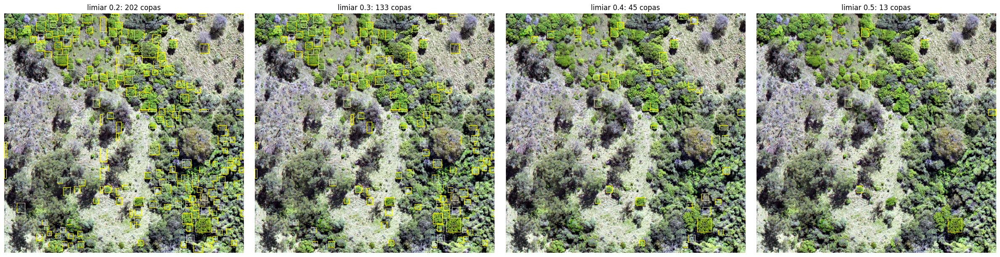

In [42]:
if CROWNS_PATH:
    todas = gpd.read_file(CROWNS_PATH).to_crs(crs)
    if "score" not in todas: todas["score"] = 1.0
else:
    from deepforest import main
    from skimage.transform import rescale
    modelo = main.deepforest()
    modelo.load_model(model_name="weecology/deepforest-tree")
    RES_DET = 0.20                                   # resolução da imagem enviada ao detector (m)
    f = RES_ALVO / RES_DET
    base = np.clip(np.moveaxis(rgb, 0, -1), 0, 255).astype("float32")   # cores originais, sem realce
    img = base if f == 1 else rescale(base, f, channel_axis=-1, preserve_range=True, anti_aliasing=True).astype("float32")
    caixas = modelo.predict_tile(image=img, patch_size=400, patch_overlap=0.25)
    caixas = caixas[caixas["score"] >= 0.1]

    def pix_para_geo(r):   # coluna/linha da imagem de detecção -> coordenadas do mapa
        xa, ya = tr * (r.xmin / f, r.ymin / f); xb, yb = tr * (r.xmax / f, r.ymax / f)
        return box(min(xa, xb), min(ya, yb), max(xa, xb), max(ya, yb))

    todas = gpd.GeoDataFrame(caixas[["score"]].reset_index(drop=True),
                             geometry=[pix_para_geo(r) for r in caixas.itertuples()], crs=crs)
    todas.to_file(f"{OUT_DIR}/copas_deepforest_todas.gpkg")

ext = [x0, x1, y0, y1]
fig, ax = plt.subplots(1, len(LIMIARES), figsize=(6 * len(LIMIARES), 6))
for a, t in zip(ax, LIMIARES):
    a.imshow(rgb_vis, extent=ext)
    todas[todas.score >= t].boundary.plot(ax=a, color="yellow", linewidth=0.8)
    a.set_title(f"limiar {t:.1f}: {(todas.score >= t).sum()} copas"); a.axis("off")
plt.tight_layout(); plt.show()

## 5b. Detecção com o detectree2 (Mask R-CNN)

O **detectree2** (Ball et al., 2023) é um Mask R-CNN, de **dois estágios**, pré-treinado para delimitar copas em florestas tropicais. Diferente do DeepForest, ele devolve o **contorno** de cada copa (segmentação de instâncias), e não só uma caixa.

Como funciona aqui:
1. o recorte RGB é salvo como GeoTIFF;
2. a imagem é cortada em tiles de 40 × 40 m com 30 m de borda extra (a sobreposição evita cortar copas, como as azeitonas da pizza);
3. o modelo prevê as copas em cada tile;
4. as predições são reunidas e as duplicatas da sobreposição são removidas.

**Cuidados:** a instalação compila a biblioteca detectron2 e leva de 5 a 10 minutos; faça antes da aula. Com GPU (Ambiente de execução > Alterar o tipo > GPU) a predição leva segundos; em CPU, alguns minutos.
Se `USAR_DETECTREE2 = False`, estas células não fazem nada e o notebook segue com o DeepForest.

In [43]:
if USAR_DETECTREE2:
    !python -m pip install -q 'git+https://github.com/facebookresearch/detectron2.git'
    !pip install -q git+https://github.com/PatBall1/detectree2.git
    !wget -q -nc https://zenodo.org/records/10522461/files/230103_randresize_full.pth -P /content/

  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


  0%|          | 0/4 [00:00<?, ?it/s]

Processando em: cpu


Stitching crowns: 100%|██████████| 4/4 [00:00<00:00, 26.03file/s]


clean_crowns: Performing spatial join...


clean_crowns: Processing candidate pairs: 100%|██████████| 1790/1790 [00:00<00:00, 3729.34it/s]


76 copas detectadas pelo detectree2


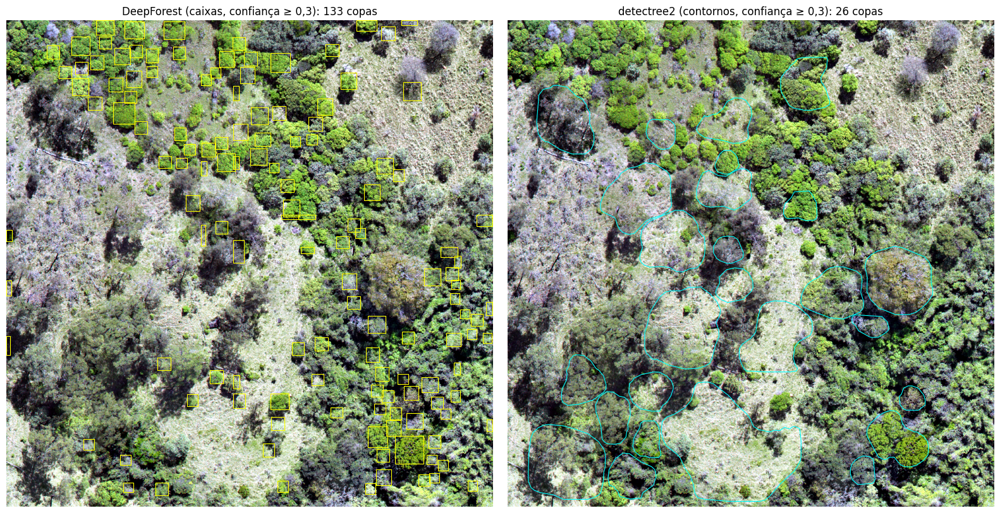

In [44]:
if USAR_DETECTREE2:
    import shutil, torch
    from detectree2.preprocessing.tiling import tile_data
    from detectree2.models.outputs import project_to_geojson, stitch_crowns, clean_crowns
    from detectree2.models.predict import predict_on_data
    from detectree2.models.train import setup_cfg
    from detectron2.engine import DefaultPredictor

    D2_DIR = "/content/detectree2"
    shutil.rmtree(D2_DIR, ignore_errors=True); os.makedirs(D2_DIR)
    img_d2 = f"{D2_DIR}/recorte_rgb.tif"
    perfil = dict(driver="GTiff", height=H, width=W, count=3, dtype="uint8", crs=crs, transform=tr)
    with rasterio.open(img_d2, "w", **perfil) as dst:
        dst.write(np.clip(rgb, 0, 255).astype("uint8"))

    tiles = f"{D2_DIR}/tiles/"
    tile_data(img_d2, tiles, buffer=30, tile_width=40, tile_height=40, dtype_bool=True)

    cfg = setup_cfg(update_model="/content/230103_randresize_full.pth")
    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    print("Processando em:", cfg.MODEL.DEVICE)
    predict_on_data(tiles, out_folder=tiles + "predictions", predictor=DefaultPredictor(cfg))
    project_to_geojson(tiles, tiles + "predictions/", tiles + "predictions_geo/")

    crowns = stitch_crowns(tiles + "predictions_geo/", 1)
    crowns = clean_crowns(crowns, 0.6, confidence=0)
    crowns = crowns.set_geometry(crowns.simplify(0.2)).to_crs(crs)
    d2 = gpd.GeoDataFrame({"score": crowns["Confidence_score"].values},
                          geometry=crowns.geometry.values, crs=crs)
    d2 = d2[d2.is_valid & ~d2.is_empty].reset_index(drop=True)
    d2.to_file(f"{OUT_DIR}/copas_detectree2_todas.gpkg")
    print(len(d2), "copas detectadas pelo detectree2")

    df_ref = todas.copy()
    fig, ax = plt.subplots(1, 2, figsize=(16, 8))
    ax[0].imshow(rgb_vis, extent=ext)
    df_ref[df_ref.score >= 0.3].boundary.plot(ax=ax[0], color="yellow", linewidth=0.8)
    ax[0].set_title(f"DeepForest (caixas, confiança ≥ 0,3): {(df_ref.score >= 0.3).sum()} copas")
    ax[1].imshow(rgb_vis, extent=ext)
    d2[d2.score >= 0.3].boundary.plot(ax=ax[1], color="cyan", linewidth=0.8)
    ax[1].set_title(f"detectree2 (contornos, confiança ≥ 0,3): {(d2.score >= 0.3).sum()} copas")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

    if SEGUIR_COM == "detectree2":
        todas = d2

**Para comentar:** onde o detectree2 foi melhor que o DeepForest (copas grandes, copas acinzentadas, contornos)? Onde foi pior? Lembre que ele foi treinado em floresta tropical fechada, uma paisagem diferente desta.

> A partir da seção 6, o notebook usa as copas do detectree2. As confianças dos dois modelos não são comparáveis entre si: escolha o limiar de novo na seção 6.

## 6. Avaliação da detecção e escolha do limiar

**Sem referência (padrão):** um zoom de 40 × 40 m no centro do recorte, com as caixas de cada limiar, para apontar falsos positivos (sombra, solo, telhado) e omissões (copas fundidas, arbustos pequenos), além da distribuição das confianças.

**Com referência (opcional):** se `REF_PONTOS` tiver um ponto por árvore num trecho da área, a célula calcula precisão, revocação e F1 por limiar. Uma caixa acerta se contém um ponto ainda não usado.

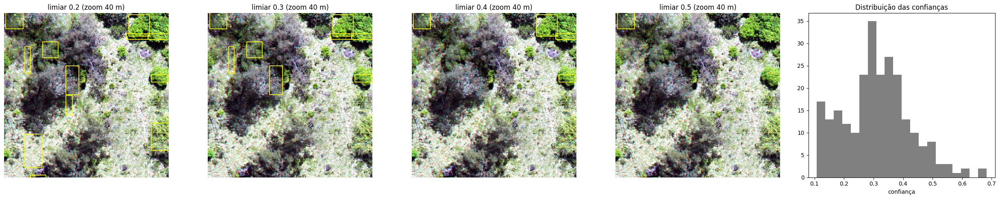

Limiar de trabalho: 0.3


In [45]:
if REF_PONTOS:
    pts = gpd.read_file(REF_PONTOS).to_crs(crs).reset_index(drop=True)
    quadro = box(*pts.total_bounds).buffer(2)
    linhas = []
    for t in LIMIARES:
        det = todas[(todas.score >= t) & todas.centroid.within(quadro)].sort_values("score", ascending=False)
        usados, vp = set(), 0
        for g in det.geometry:
            dentro = [j for j, p in enumerate(pts.geometry) if j not in usados and g.contains(p)]
            if dentro: usados.add(dentro[0]); vp += 1
        fp, fn = len(det) - vp, len(pts) - vp
        pr, rv = vp / max(vp + fp, 1), vp / max(vp + fn, 1)
        linhas.append(dict(limiar=t, VP=vp, FP=fp, FN=fn, precisao=pr, revocacao=rv, F1=2 * pr * rv / max(pr + rv, 1e-9)))
    aval = pd.DataFrame(linhas).round(2); display(aval)
    LIMIAR = float(aval.loc[aval.F1.idxmax(), "limiar"])
else:
    cx, cy, m = (x0 + x1) / 2, (y0 + y1) / 2, 20
    fig, ax = plt.subplots(1, len(LIMIARES) + 1, figsize=(5 * (len(LIMIARES) + 1), 5))
    for a, t in zip(ax, LIMIARES):
        a.imshow(rgb_vis, extent=ext)
        todas[todas.score >= t].boundary.plot(ax=a, color="yellow", linewidth=1.2)
        a.set_xlim(cx - m, cx + m); a.set_ylim(cy - m, cy + m)
        a.set_title(f"limiar {t:.1f} (zoom 40 m)"); a.axis("off")
    ax[-1].hist(todas.score, bins=20, color="gray"); ax[-1].set_xlabel("confiança"); ax[-1].set_title("Distribuição das confianças")
    plt.tight_layout(); plt.show()
    LIMIAR = 0.3       # ajuste depois de olhar o zoom
print("Limiar de trabalho:", LIMIAR)

**Para comentar:** o melhor limiar para **contar** árvores é o mesmo para **delimitar** bem cada copa? Por que não calculamos precisão e revocação sem uma referência?

## 7. Atributos por copa

Cada copa recebe médias e desvios das bandas, do NDVI e do NDRE.
- **Brutos:** R, G, B, NIR médios, sensíveis a sombra e iluminação.
- **Normalizados:** coordenadas cromáticas (r = R ÷ (R+G+B) etc.), índices e desvios, menos sensíveis ao brilho.

In [46]:
copas = todas[todas.score >= LIMIAR].reset_index(drop=True)
copas["area_m2"] = copas.geometry.area
rotulos = rasterize(((g, i + 1) for i, g in enumerate(copas.geometry)),
                    out_shape=(H, W), transform=tr, fill=0, dtype="int32")
lab = np.where(valido, rotulos, 0).ravel()
n = len(copas) + 1
cont = np.bincount(lab, minlength=n).astype("float64")

def media_desvio(arr):
    v = np.nan_to_num(arr.ravel().astype("float64"))
    s = np.bincount(lab, weights=v, minlength=n); s2 = np.bincount(lab, weights=v**2, minlength=n)
    m = s / np.maximum(cont, 1)
    return m[1:], np.sqrt(np.maximum(s2 / np.maximum(cont, 1) - m**2, 0))[1:]

soma = rgb.sum(0) + 1e-9
bandas = {"R": rgb[0], "G": rgb[1], "B": rgb[2], "NIR": escala01(nir) * 255, "NDVI": ndvi,
          "r_crom": rgb[0] / soma, "g_crom": rgb[1] / soma, "b_crom": rgb[2] / soma}
if ndre is not None:
    bandas.update({"RE": escala01(re_) * 255, "NDRE": ndre})
for nome, arr in bandas.items():
    copas[f"{nome}_media"], copas[f"{nome}_desv"] = media_desvio(arr)
copas["n_pixels"] = cont[1:]
copas["brilho"] = copas[["R_media", "G_media", "B_media"]].mean(axis=1)

# remove detecções que não são vegetação (solo, telhado, estrada) ou pequenas demais
copas = copas[(copas["n_pixels"] >= 20) & (copas["NDVI_media"] > np.nanpercentile(ndvi, 30))].reset_index(drop=True)
print(len(copas), "copas após filtro de NDVI")
copas.describe().T.round(3).head(12)

130 copas após filtro de NDVI


,count,mean,std,min,25%,50%,75%,max
score,130.0,0.392,0.078,0.302,0.337,0.371,0.428,0.683
area_m2,130.0,16.653,9.011,6.480,10.240,14.820,20.160,75.680
R_media,130.0,95.482,17.939,24.785,85.427,95.844,107.429,132.753
R_desv,130.0,39.460,7.204,9.193,35.549,38.683,43.750,61.577
G_media,130.0,112.244,19.526,30.695,102.088,113.725,125.452,147.034
G_desv,130.0,37.186,7.154,6.905,32.028,37.474,42.253,57.241
B_media,130.0,55.921,14.859,16.831,44.151,54.149,66.969,96.282
B_desv,130.0,23.284,5.679,6.612,18.973,22.818,26.604,41.028
NIR_media,130.0,150.704,42.754,0.032,123.711,158.400,180.558,227.283
NIR_desv,130.0,55.651,12.069,0.271,48.757,55.982,64.175,82.127


## 8. Agrupamento com K-means

O número de grupos é escolhido pela **silhueta** (de −1 a 1): o quanto cada copa está mais perto do próprio grupo do que do grupo vizinho.

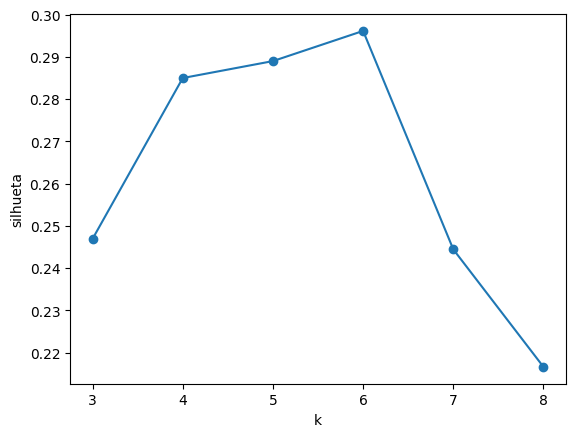

k escolhido: 6


,r_crom_media,g_crom_media,b_crom_media,NDVI_media,NDVI_desv,NIR_desv,G_desv,NDRE_media,NDRE_desv,brilho,area_m2
grupo,,,,,,,,,,,
0,0.357,0.401,0.243,0.760,0.057,43.203,31.420,0.216,0.043,91.764,15.700
1,0.339,0.424,0.236,0.841,0.040,64.287,41.634,0.253,0.057,86.143,13.058
2,0.362,0.461,0.177,0.818,0.045,56.053,36.015,0.193,0.047,87.650,19.873
3,0.295,0.438,0.267,0.759,0.072,26.557,17.751,0.279,0.063,29.937,7.893
4,0.359,0.392,0.249,0.691,0.081,60.701,46.139,0.199,0.051,101.622,15.498
5,0.335,0.376,0.289,0.809,0.786,61.438,45.374,0.272,1.571,91.327,24.000


In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ATRIB_BRUTOS = ["R_media", "G_media", "B_media", "NIR_media"]
ATRIB_NORM   = ["r_crom_media", "g_crom_media", "b_crom_media", "NDVI_media",
                "NDVI_desv", "NIR_desv", "G_desv"] + (["NDRE_media", "NDRE_desv"] if ndre is not None else [])
ATRIBUTOS = ATRIB_NORM          # depois troque para ATRIB_BRUTOS e compare

X = StandardScaler().fit_transform(copas[ATRIBUTOS])
ks = range(3, 9)
sil = [silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X)) for k in ks]
plt.plot(list(ks), sil, "o-"); plt.xlabel("k"); plt.ylabel("silhueta"); plt.show()

K = list(ks)[int(np.argmax(sil))]      # ou escolha manualmente após olhar a galeria
copas["grupo"] = KMeans(K, n_init=10, random_state=0).fit_predict(X)
print("k escolhido:", K)
copas.groupby("grupo")[ATRIBUTOS + ["brilho", "area_m2"]].mean().round(3)

**Diagnóstico:** se a média de `brilho` varia muito entre grupos, o agrupamento pode estar separando **copas iluminadas × sombreadas**, e não tipos de copa.
Compare o resultado com `ATRIB_BRUTOS` para ver esse efeito.

## 9. Mapa dos grupos

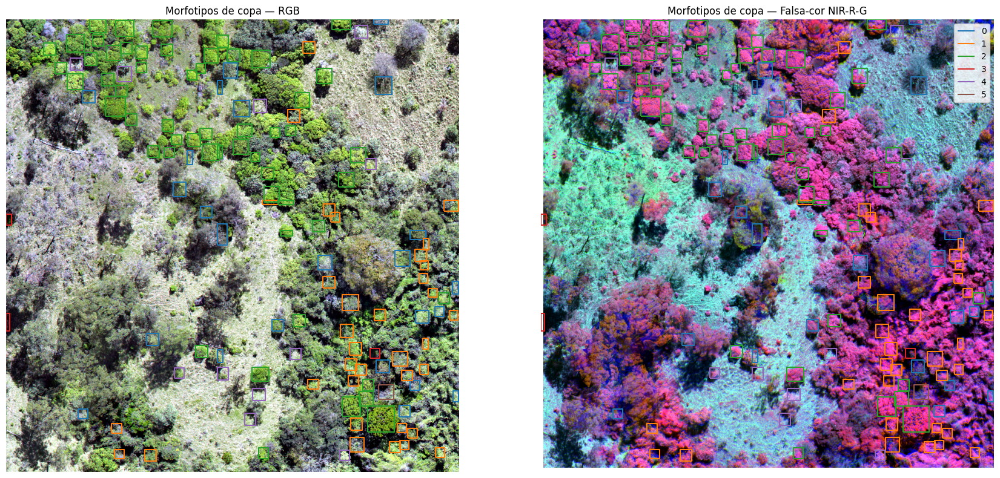

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a, base, tit in [(ax[0], rgb_vis, "RGB"), (ax[1], falsa_cor, "Falsa-cor NIR-R-G")]:
    a.imshow(base, extent=ext)
    copas.assign(geometry=copas.boundary).plot(ax=a, column="grupo", cmap="tab10", categorical=True, linewidth=1.5, legend=(a is ax[1]))
    a.set_title(f"Morfotipos de copa — {tit}"); a.axis("off")
plt.tight_layout(); plt.show()
copas.to_file(f"{OUT_DIR}/copas.gpkg")

## 10. Galeria por grupo

Cada linha é um grupo: recortes em cor verdadeira e em falsa-cor, lado a lado.

**Para comentar:** este grupo é um tipo de copa ou só copas na sombra? Que nome descritivo daríamos a ele?

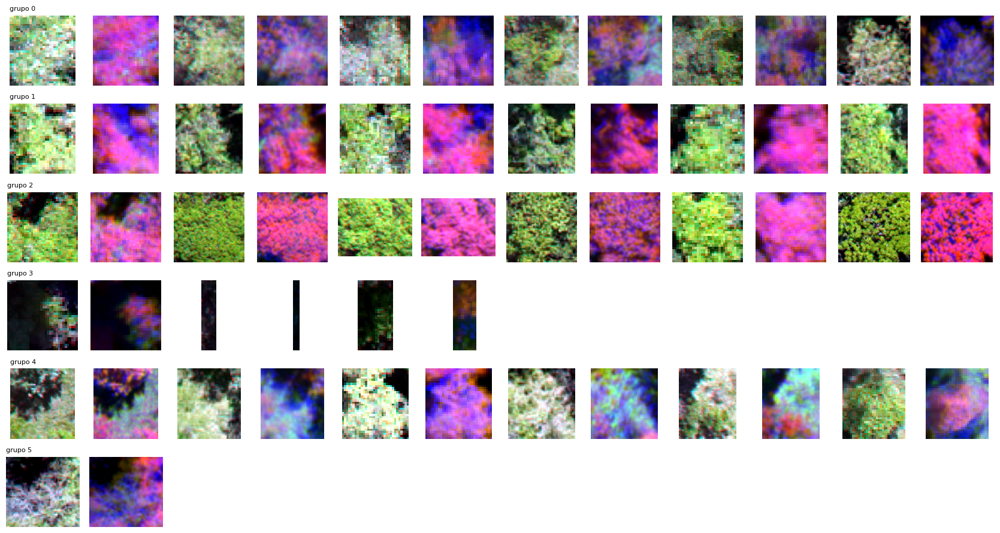

In [49]:
def recorte(geom, img):
    gx0, gy0, gx1, gy1 = geom.bounds
    c0, r0 = ~tr * (gx0, gy1); c1, r1 = ~tr * (gx1, gy0)
    return img[max(int(r0), 0):int(r1), max(int(c0), 0):int(c1)]

N = 6
fig, ax = plt.subplots(K, N * 2, figsize=(N * 2 * 1.4, K * 1.5))
for g in range(K):
    amostra = copas[copas.grupo == g].sample(min(N, (copas.grupo == g).sum()), random_state=0)
    for j in range(N):
        for k, base in enumerate([rgb_vis, falsa_cor]):
            a = ax[g, j * 2 + k]; a.axis("off")
            if j < len(amostra):
                a.imshow(recorte(amostra.geometry.iloc[j], base))
    ax[g, 0].set_title(f"grupo {g}", fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/galeria_grupos.png", dpi=150); plt.show()

## 11. Copas típicas de cada grupo (curadoria automática)

Em vez de a turma marcar copa por copa, usamos a **silhueta de cada copa**: copas com silhueta alta estão bem no meio do seu grupo (**típicas**); copas com silhueta baixa ou negativa estão na fronteira entre grupos (**duvidosas**).

As típicas viram os exemplos de treino da Aula 10; as duvidosas serão as candidatas do active learning.

Preencha `NOMES_GRUPOS` com nomes descritivos depois de olhar a galeria (ex.: `{0: "clara de textura fina", 1: "escura e densa", ...}`).

curadoria,duvidosa,tipica,All
nome_grupo,,,
grupo 0,6,18,24
grupo 1,7,28,35
grupo 2,15,41,56
grupo 3,3,0,3
grupo 4,2,9,11
grupo 5,1,0,1
All,34,96,130


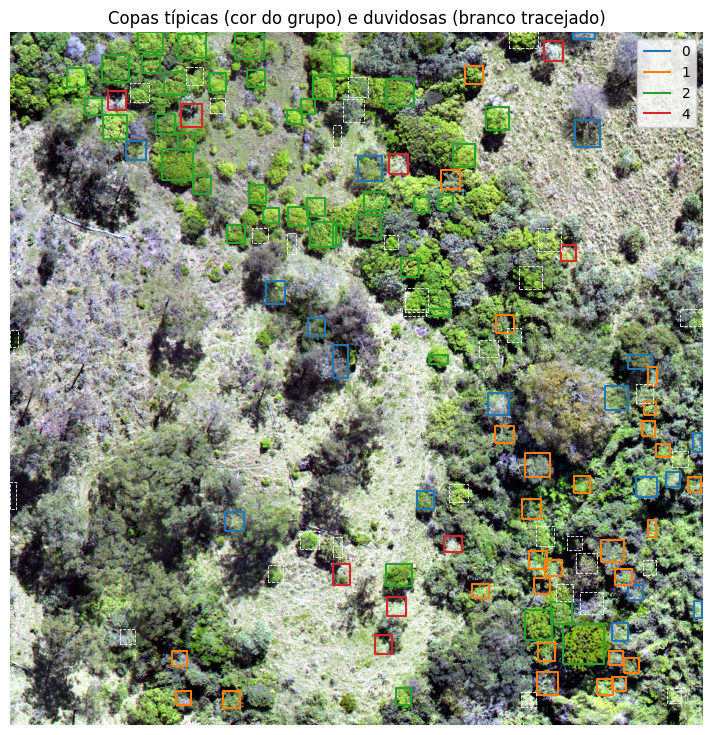

Salvos: copas.gpkg e morfotipos_curados.gpkg em /content/drive/MyDrive/Export-earth-engine/YOLO/saidas


In [50]:
from sklearn.metrics import silhouette_samples

SIL_TIPICA = 0.2
copas["silhueta"] = silhouette_samples(X, copas["grupo"])
copas["curadoria"] = np.where(copas["silhueta"] >= SIL_TIPICA, "tipica", "duvidosa")

NOMES_GRUPOS = {}          # preencha após olhar a galeria
copas["nome_grupo"] = copas["grupo"].map(NOMES_GRUPOS).fillna(copas["grupo"].map(lambda g: f"grupo {g}"))

display(pd.crosstab(copas["nome_grupo"], copas["curadoria"], margins=True))

fig, a = plt.subplots(figsize=(9, 9))
a.imshow(rgb_vis, extent=ext)
tip = copas[copas.curadoria == "tipica"]
tip.assign(geometry=tip.boundary).plot(ax=a, column="grupo", cmap="tab10", categorical=True, linewidth=1.5, legend=True)
copas[copas.curadoria == "duvidosa"].boundary.plot(ax=a, color="white", linewidth=0.6, linestyle="--")
a.set_title("Copas típicas (cor do grupo) e duvidosas (branco tracejado)"); a.axis("off")
plt.show()

copas.to_file(f"{OUT_DIR}/copas.gpkg")
copas[copas.curadoria == "tipica"].to_file(f"{OUT_DIR}/morfotipos_curados.gpkg")
print("Salvos: copas.gpkg e morfotipos_curados.gpkg em", OUT_DIR)

**Para comentar:** a curadoria automática só mede o quanto a copa se parece com o seu grupo nos atributos escolhidos. Ela não corrige um grupo que separa sol e sombra, nem uma copa mal delimitada. Por isso, numa pesquisa, a revisão humana continua necessária.

## 12. Síntese

1. Quantas copas o DeepForest encontrou e qual limiar escolhemos? Por quê?
2. Onde ele mais errou: dossel fechado, sombras, arbustos no campo?
3. Os grupos separam tipos de copa ou copas iluminadas e sombreadas? (troque `ATRIBUTOS` para `ATRIB_BRUTOS` e compare)
4. O NIR e o red edge mudaram o agrupamento? (rode sem `NIR_desv`, `NDVI_*` e `NDRE_*`)
5. Que incertezas entram aqui: delimitação, alinhamento RGB–multiespectral, iluminação, calibração, data única de voo?

**Produtos para a Aula 10:** `copas.gpkg` (todas as copas, com grupo e silhueta) e `morfotipos_curados.gpkg` (copas típicas).